In [1]:
%load_ext autoreload
%autoreload 2
import isautilities as isau
import modelsCNN as models
import numpy as np
import fmatoolbox as fma
import torch
import sklearn as sk
import joblib
import pathlib
froot = pathlib.Path().cwd() / 'Results' / 'UnitBinary'
batch_file = '/mnt/hubel-data-103/Pietro/InfraSlowNRPaper/Data/IS_intervals.batch'
do_save = False

In [2]:
session = fma.data.readBatchFile(batch_file)[0][9]
print(session)

/mnt/hubel-data-131/perceval/Rat003_20231224/Rat003_20231224.xml


In [3]:
def couplData(session,regs,lim=(-0.4,0),delay=0):

    # load data
    R = fma.regions.regions(session,states='sws',events='InfraSlowRhythm/infraslowaval')
    events, is_coupl, is_isa = isau.loadHpcPfcEvents(session,names=['ripples','down','spindles'],regions=R,
                                                     coupl=True,wait=0.5,isa=R.eventIntervals('slownr'),sleep=R.eventIntervals('sws'))

    # spikes around ripples
    spikes = R.spikes(regs=regs)
    data, t, _ = fma.analysis.PETH(spikes[:,0],events['ripples'],limits=lim,bin=0.01,groups=spikes[:,1],g_range=R.units(regs=regs)) # (event, time, unit)
    data = np.permute_dims(data,(0,2,1)) # (event, unit, time)

    return data, is_coupl['ripples'], t

In [4]:
X, y, t = couplData(session,'pfc',delay=0)

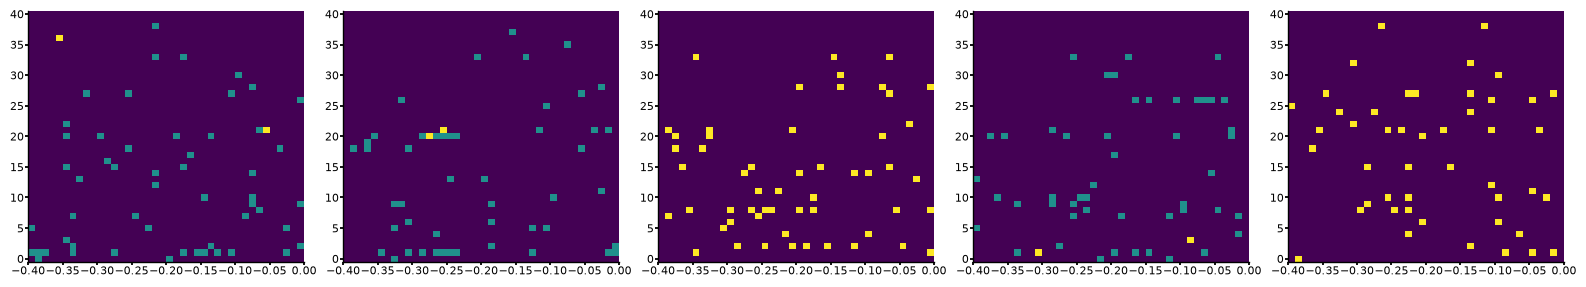

In [5]:
# see examples
plot_idx = np.arange(5) * 5 + 8
fig, ax = fma.plotting.makeFigure(n=(1,len(plot_idx)),size=(40,7))
for i, p in enumerate(plot_idx):
    fma.plotting.plotColorMap(X[p],x=t,ax=ax[i])

In [6]:
def _couplingCNN(session=None,regs=None,delay=0,model="CNN1d",train_sizes=None,fname=None,rnd_seed=None):

    # configure GPU use
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"device: {device}")

    X, y, _ = couplData(session,regs,delay=delay)
    print(f'target: {y.mean()}')
    X = torch.tensor(X,dtype=torch.float32)
    y = torch.tensor(y.astype(float),dtype=torch.float32)

    mod = model # store model name
    kf = sk.model_selection.StratifiedKFold(n_splits=5,shuffle=True,random_state=rnd_seed)
    kf = kf.split(X,y)
    train_losses = [] # (fold, epoch), only for last train size
    val_losses = []
    train_auc = [] # (fold, train size, epoch)
    test_auc = []
    print("fold  -  validation loss")
    for fold, (train_idx, val_idx) in enumerate(kf):
        if train_sizes is None: train_sizes = [len(train_idx)]
        print(f"  {fold+1}   -",end="")

        train_auc.append([])
        test_auc.append([])
        for n in train_sizes:
            train_auc[-1].append([])
            test_auc[-1].append([])
            this_train_idx = train_idx[:n]

            # split into train and validation sets
            X_train = X[this_train_idx]
            y_train = y[this_train_idx]
            X_val = X[val_idx]
            y_val = y[val_idx]

            # normalize
            m = X_train.mean(dim=(0,2),keepdim=True)
            s = X_train.std(dim=(0,2),keepdim=True)
            s = torch.clamp(s,min=1e-8)
            X_train = (X_train - m) / s
            X_val = (X_val - m) / s

            # data loaders
            train_ds = torch.utils.data.TensorDataset(X_train,y_train)
            val_ds = torch.utils.data.TensorDataset(X_val,y_val)
            train_loader = torch.utils.data.DataLoader(train_ds,batch_size=16,shuffle=True)
            val_loader = torch.utils.data.DataLoader(val_ds,batch_size=16,shuffle=False)

            # define / reset model
            model = models.loadModel(mod,n_features=X.shape[1]).to(device)
            optimizer = torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-3) # weight_decay against overfitting
            criterion = torch.nn.BCEWithLogitsLoss()
            #pos_weight = (y_train==0).sum() / (y_train==1).sum()
            #float(pos_weight>100) and print(f' pw:{pos_weight.numpy():.2f}!',end='')
            #criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))

            # track per epoch histories
            this_train_losses = [] # for this n, one value per epoch
            this_val_losses = []
            for epoch in range(50):
                # 1. train
                model.train()
                this_train_losses.append([])
                for xb, yb in train_loader:
                    optimizer.zero_grad()
                    logits = model(xb.to(device)).squeeze(-1)
                    loss = criterion(logits,yb.to(device))
                    loss.backward()
                    optimizer.step()
                    this_train_losses[-1].append(loss.item())
                this_train_losses[-1] = np.mean(this_train_losses[-1])
                # 2. validation
                model.eval()
                this_val_losses.append([])
                train_true = []
                train_prob = []
                val_true = []
                val_prob = []
                with torch.no_grad():
                    # train scores
                    for xb, yb in train_loader:
                        logits = model(xb.to(device)).squeeze(-1)
                        prob = torch.sigmoid(logits)
                        train_true.append(yb.numpy())
                        train_prob.append(prob.cpu().numpy())
                    # test set validation
                    for xb, yb in val_loader:
                        yb = yb.to(device)
                        logits = model(xb.to(device)).squeeze(-1)
                        loss = criterion(logits,yb)
                        this_val_losses[-1].append(loss.item())
                        prob = torch.sigmoid(logits)
                        val_true.append(yb.cpu().numpy())
                        val_prob.append(prob.cpu().numpy())
                this_val_losses[-1] = np.mean(this_val_losses[-1])
                train_auc[-1][-1].append(sk.metrics.roc_auc_score(np.concatenate(train_true), np.concatenate(train_prob)))
                test_auc[-1][-1].append(sk.metrics.roc_auc_score(np.concatenate(val_true), np.concatenate(val_prob)))

        # keep only losses of last n per fold
        train_losses.append(this_train_losses)
        val_losses.append(this_val_losses)
        print(f"  {this_val_losses[-1]:.4f}")

        results = {'train_sizes': np.asarray(train_sizes),
                   'train_losses': np.array(train_losses),
                   'val_losses': np.array(val_losses),
                   'train_scores': np.array(train_auc),
                   'test_scores': np.array(test_auc)}
        name = regs if (isinstance(regs,str) or len(regs)) == 1 else '_'.join(regs)
        if fname is not None: name += '_' + fname
        joblib.dump(results, froot / f"{mod}_d{delay}_{name}.joblib")

    return results

In [8]:
CNN_cv = _couplingCNN(session,regs='pfc',model='CNN1D_noregu',delay=0,train_sizes=np.arange(1000,4000,2500),rnd_seed=42)

device: cuda
target: 0.1198551201843925
fold  -  validation loss
  1   -  0.8666
  2   -  0.9464
  3   -  0.8419
  4   -  1.0263
  5   -  0.7609


/home/pietro/TestPyTorCharm/.venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/home/pietro/TestPyTorCharm/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:307: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


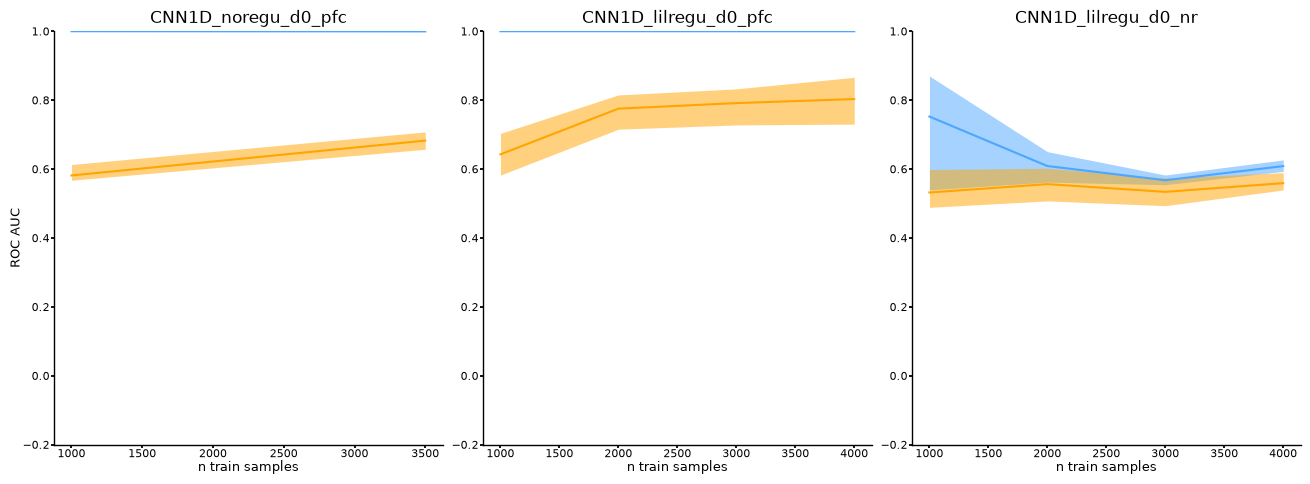

In [9]:
names = [['CNN1D_noregu_d0_pfc','CNN1D_lilregu_d0_pfc','CNN1D_lilregu_d0_nr']]
fig, ax = fma.plotting.makeFigure(n=(len(names),len(names[0])),size=(33,12))
ax = np.array(ax,ndmin=2)
for i, names1 in enumerate(names):
    for j, name in enumerate(names1):
        res = joblib.load(froot / f'{name}.joblib')
        fma.plotting.semPlot(res["train_sizes"],res["train_scores"][:,:,-1],color='#4da6ff',ax=ax[i,j])
        fma.plotting.semPlot(res["train_sizes"],res["test_scores"][:,:,-1],color='orange',ax=ax[i,j])
        ax[i,j].set(title=name,ylim=[-0.2,1])
fma.plotting.setProp(ax[0],xlabel='n train samples'); fma.plotting.setProp(ax[:,0],ylabel='ROC AUC')

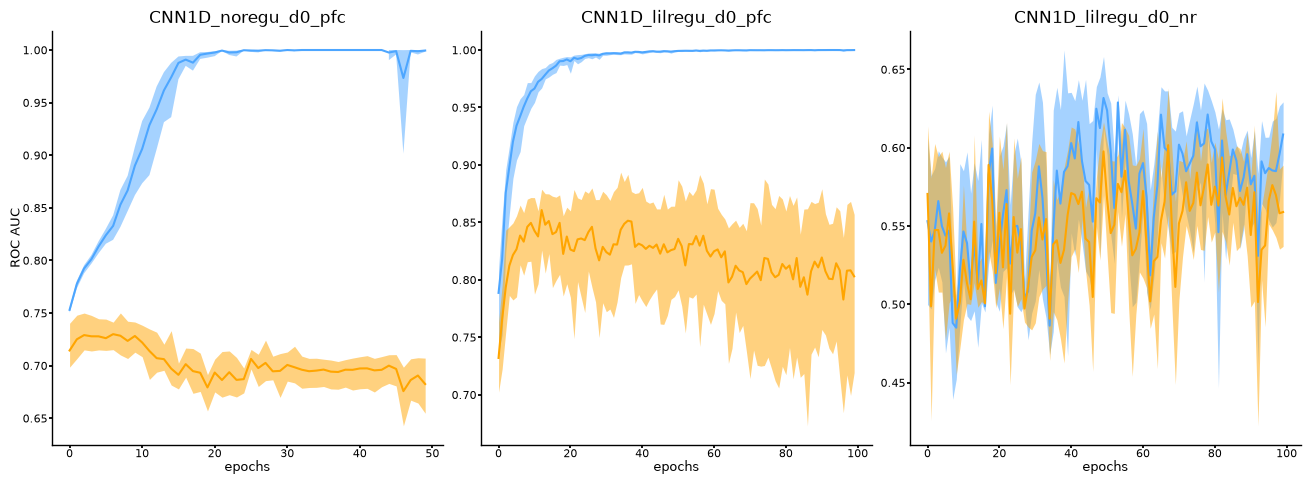

In [10]:
names = [['CNN1D_noregu_d0_pfc','CNN1D_lilregu_d0_pfc','CNN1D_lilregu_d0_nr']]
fig, ax = fma.plotting.makeFigure(n=(len(names),len(names[0])),size=(33,12))
ax = np.array(ax,ndmin=2)
for i, names1 in enumerate(names):
    for j, name in enumerate(names1):
        res = joblib.load(froot / f'{name}.joblib')
        fma.plotting.semPlot(range(res["train_scores"].shape[-1]),res["train_scores"][:,-1,:],color='#4da6ff',ax=ax[i,j])
        fma.plotting.semPlot(range(res["test_scores"].shape[-1]),res["test_scores"][:,-1,:],color='orange',ax=ax[i,j])
        ax[i,j].set(title=name)
fma.plotting.setProp(ax[0],xlabel='epochs'); fma.plotting.setProp(ax[:,0],ylabel='ROC AUC')

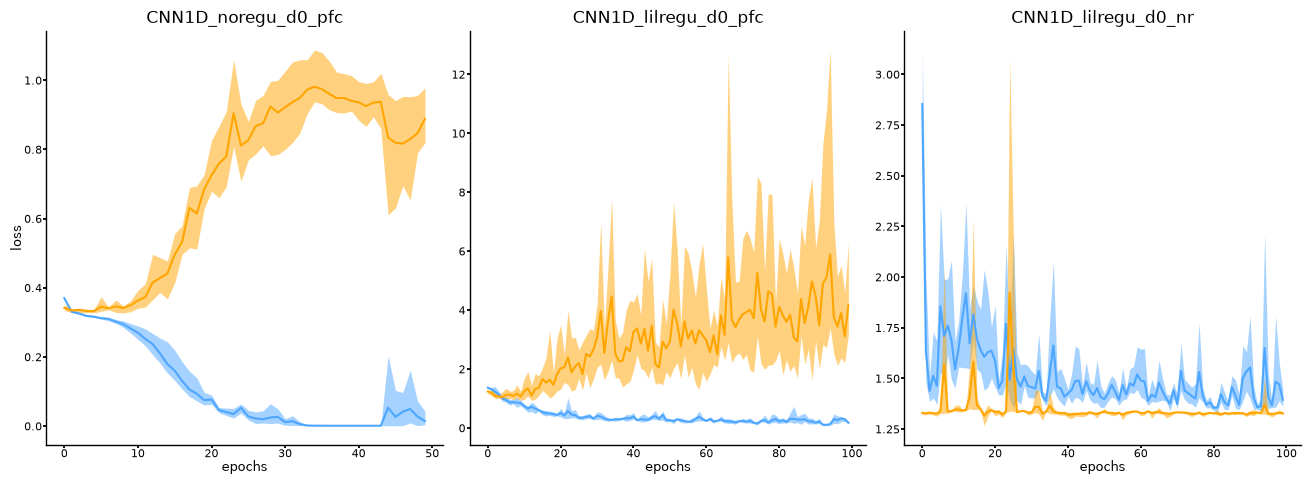

In [11]:
names = [['CNN1D_noregu_d0_pfc','CNN1D_lilregu_d0_pfc','CNN1D_lilregu_d0_nr']]
fig, ax = fma.plotting.makeFigure(n=(len(names),len(names[0])),size=(33,12))
ax = np.array(ax,ndmin=2)
for i, names1 in enumerate(names):
    for j, name in enumerate(names1):
        res = joblib.load(froot / f'{name}.joblib')
        fma.plotting.semPlot(range(res["train_losses"].shape[1]),res["train_losses"],color='#4da6ff',ax=ax[i,j])
        fma.plotting.semPlot(range(res["val_losses"].shape[1]),res["val_losses"],color='orange',ax=ax[i,j])
        ax[i,j].set(title=name)
fma.plotting.setProp(ax[0],xlabel='epochs'); fma.plotting.setProp(ax[:,0],ylabel='loss')